## Problema 8: ¿Qué pasó con las calificaciones de Carlos?
Te encuentras analizando las calificaciones de tus estudiantes y decides visualizar los datos en un gráfico de barras para tener una visión más clara. Sin embargo, te das cuenta de que algo no cuadra. Carlos, uno de tus estudiantes, aparece con una sola calificación de 8 en el gráfico, pero tú recuerdas claramente que él tiene dos calificaciones registradas, una de 8 y otra de 6.

Te preguntas, ¿qué está pasando? ¿Cómo puedes asegurarte de que todas las calificaciones de Carlos (y de cualquier otro estudiante que pueda tener más de una calificación) sean tenidas en cuenta en tu gráfico?

---

*Solución*El gráfico de barras que generaste originalmente toma cada calificación como una entrada individual. Si hay más de una entrada con el mismo nombre, sólo se considera una de ellas. Por tanto, necesitas una forma de agrupar todas las calificaciones de cada estudiante y luego graficar la calificación promedio de cada uno.

Aquí es donde entra en juego la función groupby de Pandas. Esta función te permite agrupar tus datos según algún criterio. En este caso, quieres agrupar los datos por el nombre del estudiante. Luego puedes calcular el promedio de las calificaciones para cada estudiante y finalmente visualizar estos datos.

Aquí está el código revisado que resuelve tu problema:


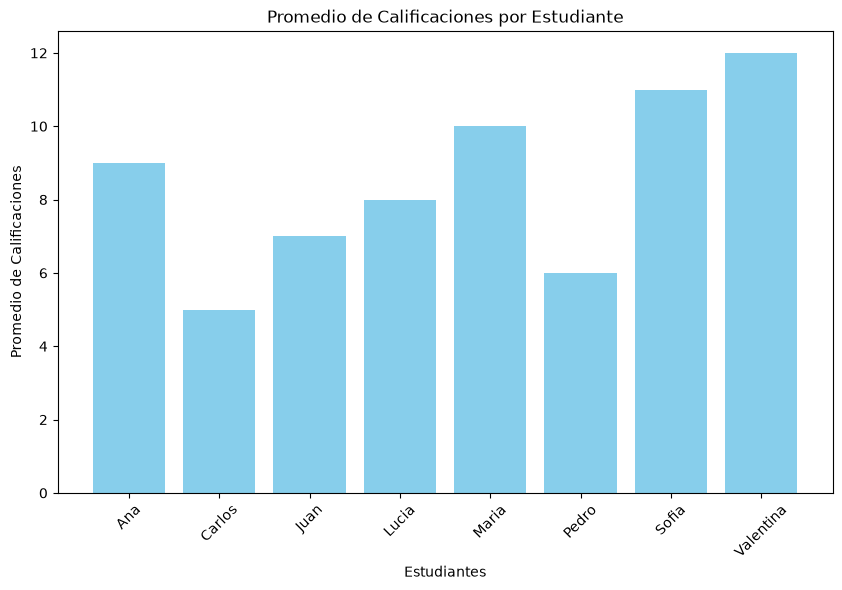

In [ ]:
# Agrupamos por nombre y calculamos el promedio de las calificaciones
df_agrupado = df.groupby('Nombre')['Calificacion'].mean().reset_index()

# Ordenamos el DataFrame por la columna 'Calificacion'
#df_agrupado = df_agrupado.sort_values('Calificacion', ascending=False)
# Descomenta lo anterior luego de probar la solución como se plantea

# Creamos el gráfico de barras con los datos agrupados
plt.figure(figsize=(10, 6))
plt.bar(df_agrupado['Nombre'], df_agrupado['Calificacion'], color='skyblue')
plt.title('Promedio de Calificaciones por Estudiante')
plt.xlabel('Estudiantes')
plt.ylabel('Promedio de Calificaciones')
plt.xticks(rotation=45)
plt.show()


===== ANALISIS DE CALIFICACIONES =====

===== CALIFICACIONES ORIGINALES =====
   Nombre  Calificacion
      Ana             9
     Juan             7
    Maria            10
    Pedro             6
    Lucia             8
    Sofia            11
   Carlos             8
   Carlos             6
Valentina            12
      Ana            10
     Juan             9

===== PROMEDIOS POR ESTUDIANTE =====
   Nombre  Calificacion  Cantidad de notas
Valentina          12.0                  1
    Sofia          11.0                  1
    Maria          10.0                  1
      Ana           9.5                  2
     Juan           8.0                  2
    Lucia           8.0                  1
   Carlos           7.0                  2
    Pedro           6.0                  1

===== CALIFICACIONES DE CARLOS =====
Nombre  Calificacion
Carlos             8
Carlos             6

Promedio de Carlos: 7.00
Promedio general: 8.94


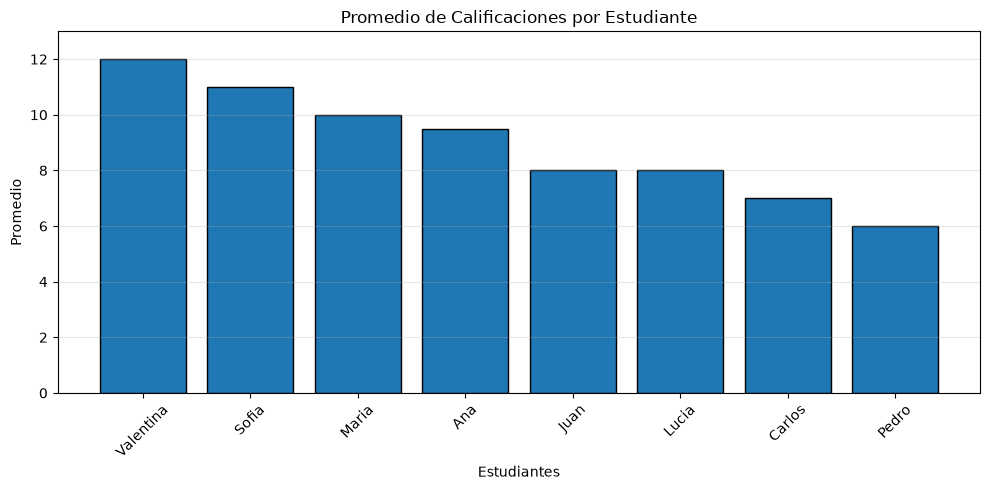

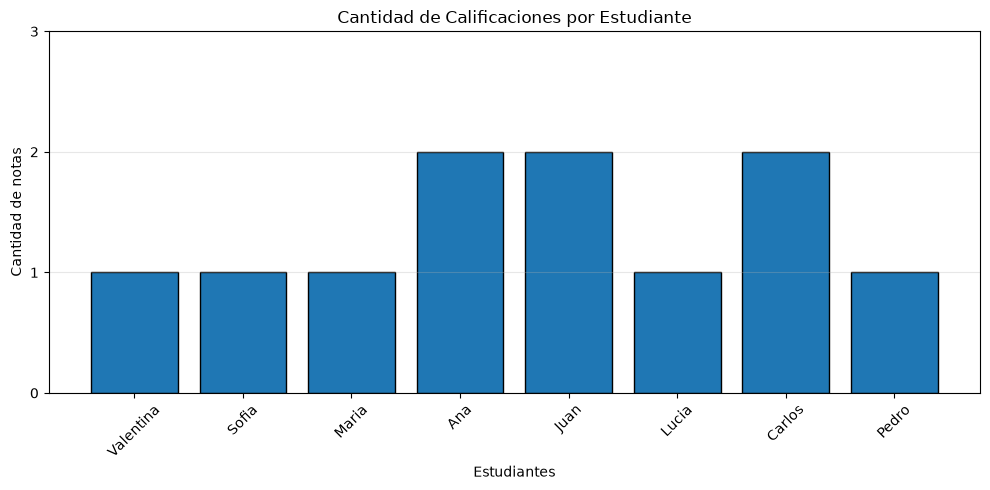


Archivos creados correctamente.
===== FIN DEL PROGRAMA =====


In [ ]:

# ==========================================
# PROBLEMA 8: ¿QUE PASO CON LAS NOTAS DE CARLOS?
# ==========================================

import pandas as pd
import matplotlib.pyplot as plt

print("===== ANALISIS DE CALIFICACIONES =====")

# 1. Creamos los datos de los estudiantes
# Algunos tienen mas de una calificacion

estudiantes = {
    "Nombre": [
        "Ana", "Juan", "Maria", "Pedro",
        "Lucia", "Sofia", "Carlos", "Carlos",
        "Valentina", "Ana", "Juan"
    ],
    "Calificacion": [
        9, 7, 10, 6, 8, 11, 8, 6, 12, 10, 9
    ]
}

# 2. Creamos el archivo CSV
df = pd.DataFrame(estudiantes)
df.to_csv("calificaciones_problema8.csv", index=False)

# 3. Leemos el archivo CSV
df = pd.read_csv("calificaciones_problema8.csv")

print("\n===== CALIFICACIONES ORIGINALES =====")
print(df.to_string(index=False))

# 4. Agrupamos las calificaciones por estudiante
# y calculamos el promedio individual

df_agrupado = (
    df.groupby("Nombre")["Calificacion"]
    .mean()
    .reset_index()
)

# 5. Agregamos la cantidad de notas de cada alumno
cantidad_notas = (
    df.groupby("Nombre")["Calificacion"]
    .count()
    .reset_index(name="Cantidad de notas")
)

df_agrupado = df_agrupado.merge(
    cantidad_notas,
    on="Nombre"
)

# 6. Ordenamos de mayor a menor promedio
df_agrupado = df_agrupado.sort_values(
    "Calificacion",
    ascending=False
)

print("\n===== PROMEDIOS POR ESTUDIANTE =====")
print(df_agrupado.to_string(index=False))

# 7. Mostramos las notas de Carlos
notas_carlos = df[df["Nombre"] == "Carlos"]

print("\n===== CALIFICACIONES DE CARLOS =====")
print(notas_carlos.to_string(index=False))

promedio_carlos = notas_carlos["Calificacion"].mean()

print(f"\nPromedio de Carlos: {promedio_carlos:.2f}")

# 8. Calculamos el promedio general de estudiantes
promedio_general = df_agrupado["Calificacion"].mean()

print(f"Promedio general: {promedio_general:.2f}")

# 9. Creamos un grafico de barras
plt.figure(figsize=(10, 5))

plt.bar(
    df_agrupado["Nombre"],
    df_agrupado["Calificacion"],
    edgecolor="black"
)

plt.title("Promedio de Calificaciones por Estudiante")
plt.xlabel("Estudiantes")
plt.ylabel("Promedio")
plt.xticks(rotation=45)
plt.ylim(0, 13)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig("promedios_estudiantes.png")
plt.show()

# 10. Creamos un grafico de cantidad de notas
plt.figure(figsize=(10, 5))

plt.bar(
    df_agrupado["Nombre"],
    df_agrupado["Cantidad de notas"],
    edgecolor="black"
)

plt.title("Cantidad de Calificaciones por Estudiante")
plt.xlabel("Estudiantes")
plt.ylabel("Cantidad de notas")
plt.xticks(rotation=45)
plt.yticks(range(0, 4))
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig("cantidad_calificaciones.png")
plt.show()

# 11. Guardamos los promedios en un archivo CSV
df_agrupado.to_csv(
    "promedios_estudiantes.csv",
    index=False
)

print("\nArchivos creados correctamente.")
print("===== FIN DEL PROGRAMA =====")
